In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded")

Libraries loaded


In [3]:
# Download the Telco Customer Churn dataset
import urllib.request
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
urllib.request.urlretrieve(url, 'WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Read and display the dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [7]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [9]:
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [10]:
df = df.dropna()
df.shape

(7032, 21)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['ChurnFlag'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['ChurnFlag'].mean()

/tmp/ipykernel_4203/2399899700.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ChurnFlag'] = df['Churn'].map({'Yes': 1, 'No': 0})


np.float64(0.26578498293515357)

In [13]:
(df.groupby('Contract')['ChurnFlag'].mean() * 100).round(1)

,ChurnFlag
Contract,
Month-to-month,42.7
One year,11.3
Two year,2.8


In [14]:
(df.groupby('InternetService')['ChurnFlag'].mean() * 100).round(1)

,ChurnFlag
InternetService,
DSL,19.0
Fiber optic,41.9
No,7.4


In [15]:
(df.groupby('PaymentMethod')['ChurnFlag'].mean() * 100).round(1)

,ChurnFlag
PaymentMethod,
Bank transfer (automatic),16.7
Credit card (automatic),15.3
Electronic check,45.3
Mailed check,19.2


In [16]:
df['TenureGroup'] = pd.cut(df['tenure'],
                           bins=[0, 12, 24, 48, 72],
                           labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months'])

(df.groupby('TenureGroup', observed=True)['ChurnFlag'].mean() * 100).round(1)

/tmp/ipykernel_4203/784869942.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['TenureGroup'] = pd.cut(df['tenure'],


,ChurnFlag
TenureGroup,
0-12 months,47.7
13-24 months,28.7
25-48 months,20.4
49-72 months,9.5


In [17]:
df.groupby('Churn')[['tenure', 'MonthlyCharges']].mean().round(1)

,tenure,MonthlyCharges
Churn,,
No,37.7,61.3
Yes,18.0,74.4


In [18]:
sns.set_style('whitegrid')

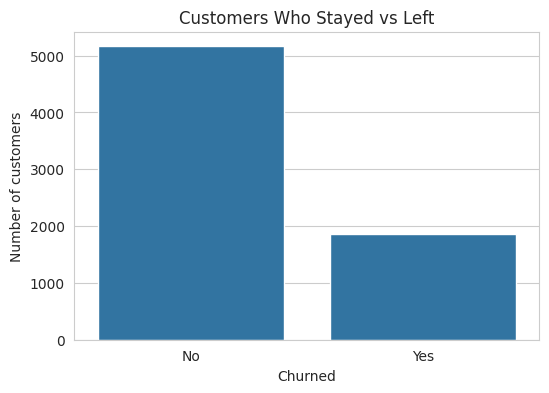

In [19]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Customers Who Stayed vs Left')
plt.xlabel('Churned')
plt.ylabel('Number of customers')
plt.savefig('chart1_churn_count.png', dpi=150, bbox_inches='tight')
plt.show()

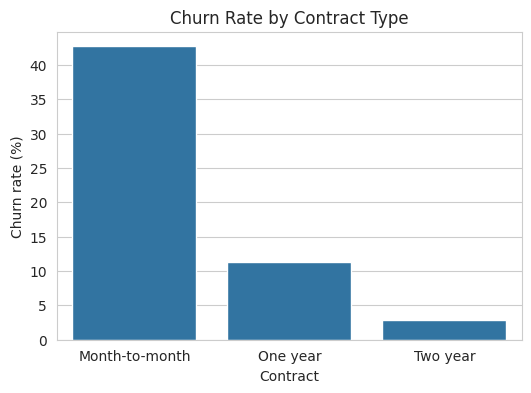

In [20]:
rate = df.groupby('Contract')['ChurnFlag'].mean() * 100

plt.figure(figsize=(6, 4))
sns.barplot(x=rate.index, y=rate.values)
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract')
plt.ylabel('Churn rate (%)')
plt.savefig('chart2_contract.png', dpi=150, bbox_inches='tight')
plt.show()

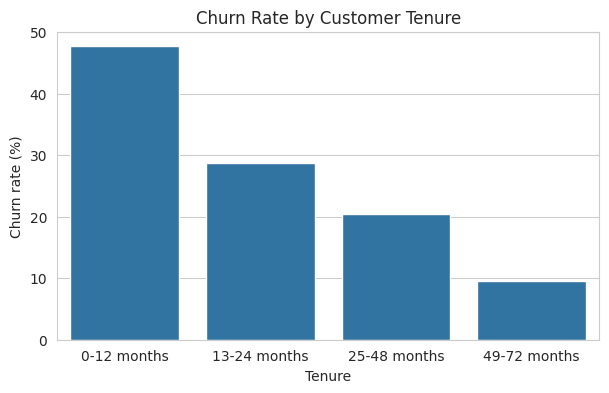

In [21]:
rate = df.groupby('TenureGroup', observed=True)['ChurnFlag'].mean() * 100

plt.figure(figsize=(7, 4))
sns.barplot(x=rate.index, y=rate.values)
plt.title('Churn Rate by Customer Tenure')
plt.xlabel('Tenure')
plt.ylabel('Churn rate (%)')
plt.savefig('chart3_tenure.png', dpi=150, bbox_inches='tight')
plt.show()

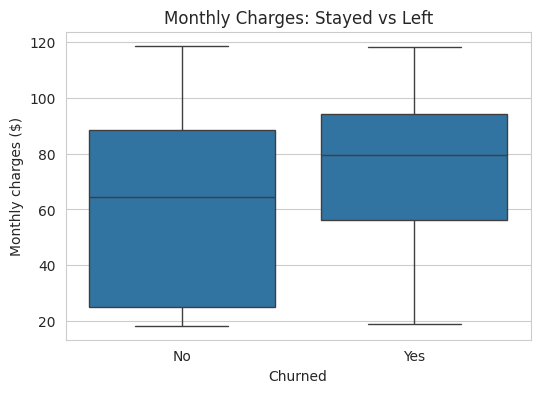

In [22]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges: Stayed vs Left')
plt.xlabel('Churned')
plt.ylabel('Monthly charges ($)')
plt.savefig('chart4_charges.png', dpi=150, bbox_inches='tight')
plt.show()

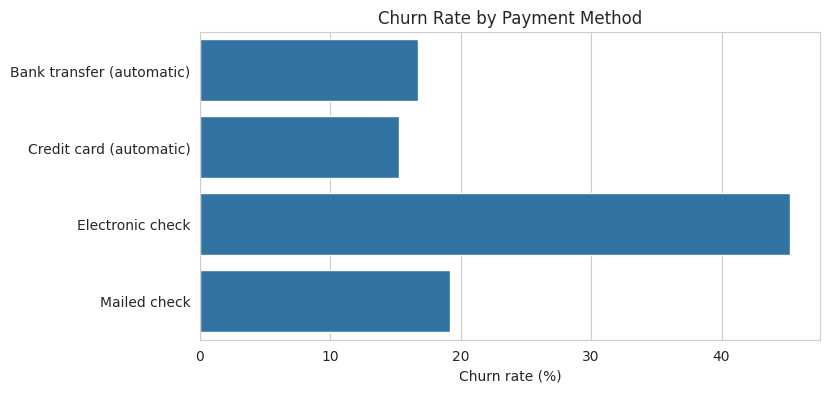

In [23]:
rate = df.groupby('PaymentMethod')['ChurnFlag'].mean() * 100

plt.figure(figsize=(8, 4))
sns.barplot(x=rate.values, y=rate.index)
plt.title('Churn Rate by Payment Method')
plt.xlabel('Churn rate (%)')
plt.ylabel('')
plt.savefig('chart5_payment.png', dpi=150, bbox_inches='tight')
plt.show()

# Customer Churn Analysis

**Goal:** Find out why telecom customers leave and which groups are most at risk.
**Tools:** Python, Pandas, Matplotlib, Seaborn
**Dataset:** Telco Customer Churn (Kaggle), 7,043 customers and 21 columns

## Data Cleaning

- Converted `TotalCharges` from text to numbers
- Found 11 missing values in `TotalCharges`, all from new customers with 0 months of tenure
- Removed those 11 rows, leaving 7,032 customers
- Checked for duplicates (none found)
- Created a `ChurnFlag` column (1 = left, 0 = stayed) to calculate churn rates

## Key Findings

1. **Overall churn rate:** __% of customers left.
2. **Contract type:** Month-to-month customers churn at __%, compared with __% for one-year and __% for two-year contracts.
3. **Tenure:** Customers in their first 12 months churn at __%, falling to __% after 4 years.
4. **Internet service:** Fiber optic customers churn at __%, the highest of the three groups.
5. **Payment method:** Electronic check users churn at __%, against about __% for other methods.
6. **Monthly charges:** Customers who left paid an average of $__ per month, compared with $__ for those who stayed.

## Recommendations

- Offer discounts or incentives to move month-to-month customers to one-year or two-year contracts.
- Focus retention efforts on customers in their first year, for example with check-in calls or onboarding offers.
- Investigate fiber optic service quality and pricing, since this group leaves most often.
- Encourage electronic check users to switch to automatic payment methods.

## Limitations

- This analysis shows patterns, not proof of cause.
- The dataset is a snapshot and has no customer feedback or reasons for leaving.
- No predictive model was built. A next step would be training a model to predict churn.